# Comparaison AE vs PCA — erreurs de reconstruction

On compare deux façons de résumer une cellule à **50 nombres** :

- une **PCA** (scikit-learn) : projection linéaire, optimale au sens des moindres carrés ;
- un **autoencodeur** (PyTorch, même architecture que `2-EA`) : goulot non linéaire (`Tanh`).

Protocole, pour que la comparaison soit honnête :

2. **même dimension de représentation** : `D = 50` pour les deux méthodes ;
3. **mêmes cellules d'entraînement** : les deux modèles sont ajustés sur le train uniquement (80 % des cellules, découpage stratifié sur `celltype`) ;
4. **évaluation sur des cellules non vues** : l'erreur de reconstruction (MSE) est mesurée sur le train *et* sur la validation, par `PCA.inverse_transform()` pour la PCA et par la sortie du décodeur pour l'AE.

Une référence supplémentaire est affichée : la MSE obtenue en prédisant simplement, pour chaque gène, sa moyenne calculée sur le train. Sans elle, une MSE de 0,6 ne veut rien dire.

In [ ]:
import os
import random

import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
import time


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Charger les résultats
pca = np.load("results/resultats_PCA.npz")
ae = np.load("results/resultats_AE.npz")

In [ ]:
# PCA
Z_pca_train = pca["Z_train"]
Z_pca_val = pca["Z_val"]

mse_pca_train = float(pca["mse_train"])
mse_pca_val = float(pca["mse_val"])

# AE simple
Z_ae_train = ae["Z_train"]
Z_ae_val = ae["Z_val"]

mse_ae_train = float(ae["mse_train"])
mse_ae_val = float(ae["mse_val"])

# AE profond
Z_ae_profond_train = ae["Z_train_profond"]
Z_ae_profond_val = ae["Z_val_profond"]

mse_ae_profond_train = float(ae["mse_train_profond"])
mse_ae_profond_val = float(ae["mse_val_profond"])

## Comparaison des erreurs de reconstruction

Toutes les MSE sont calculées sur la **même matrice cible** (2 000 gènes log-normalisés) et dans la même unité, donc directement comparables.

In [ ]:
comparaison = pd.DataFrame(
    {
        "MSE train": [mse_ref_train, mse_pca_train, mse_ae_train],
        "MSE validation": [mse_ref_val, mse_pca_val, mse_ae_val],
    },
    index=["Moyenne par gène (référence)", f"PCA ({D} composantes)", f"Autoencodeur (latent {D})"],
)

comparaison["écart validation - train"] = (
    comparaison["MSE validation"] - comparaison["MSE train"]
)

print(comparaison.round(4))

meilleure = comparaison["MSE validation"].idxmin()
print(f"\nMeilleure reconstruction en validation : {meilleure}")
print(
    "Réduction de l'erreur par rapport à la référence : "
    f"PCA {100 * (1 - mse_pca_val / mse_ref_val):.1f} % | "
    f"AE {100 * (1 - mse_ae_val / mse_ref_val):.1f} %"
)

                              MSE train  MSE validation  écart validation - train
Moyenne par gène (référence)     0.1883          0.1887                    0.0005
PCA (50 composantes)             0.0719          0.0721                    0.0001
Autoencodeur (latent 50)         0.0732          0.0736                    0.0004

Meilleure reconstruction en validation : PCA (50 composantes)
Réduction de l'erreur par rapport à la référence : PCA 61.8 % | AE 61.0 %


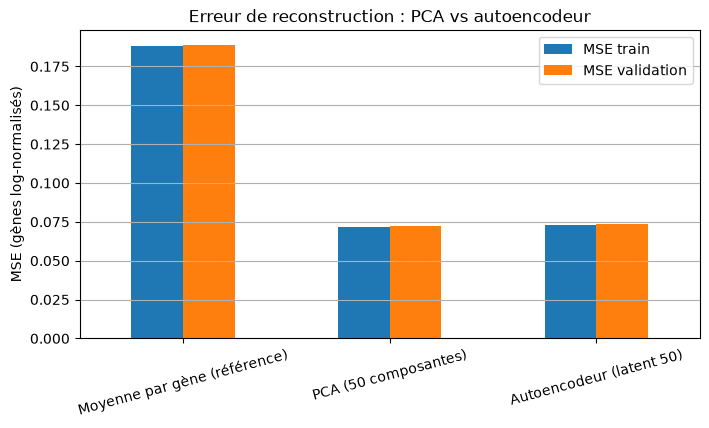

In [ ]:
comparaison[["MSE train", "MSE validation"]].plot.bar(figsize=(8, 4))
plt.ylabel("MSE (gènes log-normalisés)")
plt.title("Erreur de reconstruction : PCA vs autoencodeur")
plt.xticks(rotation=15)
plt.grid(axis="y")
plt.show()

## 6. Les représentations en 2D

Même nombre de dimensions ne veut pas dire même qualité de représentation : on projette les deux espaces latents (PCA 50 et latent AE 50) en 2D par une PCA, et on colorie par type cellulaire. Les structures qui apparaissent sont celles que le clustering pourra exploiter.

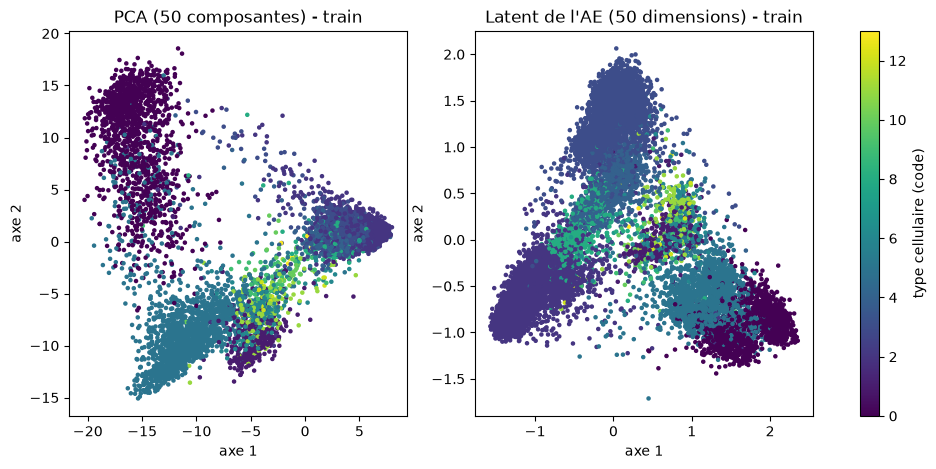

In [ ]:
labels = train.obs["celltype"].astype("category")
codes = labels.cat.codes.to_numpy()
Z_pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(Z_pca_train)
Z_ae_2d = PCA(n_components=2, random_state=SEED).fit_transform(Z_ae_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(Z_pca_2d[:, 0], Z_pca_2d[:, 1], c=codes, cmap="viridis", s=5)
axes[0].set_title(f"PCA ({D} composantes) - train")
axes[0].set_xlabel("axe 1")
axes[0].set_ylabel("axe 2")

im = axes[1].scatter(Z_ae_2d[:, 0], Z_ae_2d[:, 1], c=codes, cmap="viridis", s=5)
axes[1].set_title(f"Latent de l'AE ({D} dimensions) - train")
axes[1].set_xlabel("axe 1")
axes[1].set_ylabel("axe 2")

fig.colorbar(im, ax=axes, label="type cellulaire (code)")
plt.show()

## 7. À retenir

- La PCA est **optimale parmi les projections linéaires** de dimension 50 : elle minimise exactement l'erreur de reconstruction au carré sur le train. Un AE ne peut la battre qu'en exploitant une **non-linéarité** réelle dans les données.
- Sur ce jeu (13 105 cellules d'entraînement, 2 000 gènes, 50 dimensions), la PCA est difficile à battre : l'AE n'apporte un gain que si la structure non linéaire compense le coût d'estimation de ses 100 000+ paramètres. Pistes si l'on veut aller plus loin : plus d'époques, régularisation (`weight_decay`), latent plus grand, ou plusieurs couches cachées.
- L'écart entre MSE train et MSE validation indique la **capacité de généralisation** : un écart large = mémorisation.
- Les deux méthodes ont vu exactement les mêmes cellules, la même matrice et la même dimension : les MSE sont comparables terme à terme.
- Limite à mentionner : la sélection des 2 000 gènes variables a été faite en amont sur toutes les cellules (le fichier `preprocessed.h5ad` ne contient déjà que ces gènes). Le découpage train/validation, lui, est bien respecté pour l'ajustement et l'évaluation des deux méthodes.